### Setup

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.model_selection import StratifiedKFold

from credit_default_risk.config import (
    ID_COL,
    TARGET_COL,
    FINAL_SELECTED_COLUMNS,
    PROCESSED_TRAIN_PATH,
    PROCESSED_TEST_PATH,
)
from credit_default_risk.helper import select_final_features
from credit_default_risk.features import (
    prepare_catboost_frame,
    prepare_lightgbm_frame,
)
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [2]:
train_df = pd.read_parquet(PROCESSED_TRAIN_PATH)
test_ids = pd.read_parquet(
    PROCESSED_TEST_PATH,
    columns=[ID_COL],
)[ID_COL]

In [3]:
required = {ID_COL, TARGET_COL}
missing = required - set(train_df.columns)
if missing:
    raise ValueError(f"Training data is missing: {sorted(missing)}")

if train_df[ID_COL].isna().any() or train_df[ID_COL].duplicated().any():
    raise ValueError("Training SK_ID_CURR must be unique and non-null.")

if train_df[TARGET_COL].isna().any():
    raise ValueError("Training TARGET contains missing labels.")

if not train_df[TARGET_COL].isin([0, 1]).all():
    raise ValueError("TARGET must contain only 0 and 1.")

if train_df[ID_COL].isin(test_ids).any():
    raise ValueError("Train and test contain overlapping SK_ID_CURR values.")

print("Training rows:", len(train_df))
print("Default rate:", f"{train_df[TARGET_COL].mean():.2%}")
display(train_df[TARGET_COL].value_counts().sort_index())

Training rows: 246008
Default rate: 8.07%


TARGET
0    226148
1     19860
Name: count, dtype: int64

In [4]:
y = train_df[TARGET_COL].astype("int8")
X = select_final_features(train_df)

assert X.columns.tolist() == FINAL_SELECTED_COLUMNS
assert ID_COL not in X.columns
assert TARGET_COL not in X.columns

print("Feature matrix:", X.shape)
print("Target:", y.shape)
display(X.head())


Feature matrix: (246008, 60)
Target: (246008,)


,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,...,PREV_APPROVAL_RATE,CREDIT_CARD_AVG_UTILIZATION,CREDIT_CARD_AVG_BALANCE,INSTALLMENT_LATE_PAYMENT_RATE,AGE_YEARS,EMPLOYMENT_YEARS,CREDIT_TO_INCOME_RATIO,ANNUITY_TO_INCOME_RATIO,GOODS_TO_CREDIT_RATIO,CREDIT_TO_ANNUITY_RATIO
0,Cash loans,F,0,0,2,13189.5,180000.0,Unaccompanied,Higher education,Married,...,1.000000,0.346744,213473.232857,0.0,33.670089,2.590007,2.528000,0.146550,0.791139,17.250085
1,Cash loans,M,1,1,0,13095.0,135000.0,Unaccompanied,Secondary / secondary special,Married,...,0.666667,NaN,NaN,0.0,42.094456,0.251882,1.797000,0.145500,0.834725,12.350515
2,Cash loans,M,0,1,0,26307.0,553500.0,"Spouse, partner",Secondary / secondary special,Single / not married,...,1.000000,NaN,NaN,0.0,52.859685,4.506502,5.398867,0.194867,0.759419,27.705440
3,Cash loans,M,0,0,0,34636.5,391500.0,Unaccompanied,Secondary / secondary special,Single / not married,...,0.750000,NaN,NaN,0.0,48.709103,4.520192,3.512467,0.256567,0.825631,13.690269
4,Cash loans,F,0,1,0,27558.0,225000.0,Unaccompanied,Incomplete higher,Single / not married,...,0.500000,NaN,NaN,0.0,23.233402,2.674880,1.415000,0.153100,0.883392,9.242325


In [5]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)
dev_idx, val_idx = next(cv.split(X, y))

X_dev_raw = X.iloc[dev_idx].copy()
X_val_raw = X.iloc[val_idx].copy()
y_dev = y.iloc[dev_idx].copy()
y_val = y.iloc[val_idx].copy()

print("Development:", X_dev_raw.shape, f"default rate={y_dev.mean():.2%}")
print("Validation: ", X_val_raw.shape, f"default rate={y_val.mean():.2%}")

Development: (196806, 60) default rate=8.07%
Validation:  (49202, 60) default rate=8.07%


In [6]:
X_dev_cb = prepare_catboost_frame(X_dev_raw)
X_val_cb = prepare_catboost_frame(X_val_raw)

X_dev_lgbm = prepare_lightgbm_frame(X_dev_raw)
X_val_lgbm = prepare_lightgbm_frame(X_val_raw)

cat_cols_cb = X_dev_cb.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

cat_cols_lgbm = X_dev_lgbm.select_dtypes(
    include="category"
).columns.tolist()

assert X_dev_cb.columns.tolist() == X_val_cb.columns.tolist()
assert X_dev_lgbm.columns.tolist() == X_val_lgbm.columns.tolist()
assert X_dev_cb.columns.tolist() == X_dev_lgbm.columns.tolist()

print("Features:", X_dev_cb.shape[1])
print("CatBoost categorical columns:", len(cat_cols_cb))
print("LightGBM categorical columns:", len(cat_cols_lgbm))

Features: 60
CatBoost categorical columns: 8
LightGBM categorical columns: 8


### Setup Experiment Tracking

In [7]:
import mlflow
from sklearn.metrics import average_precision_score, roc_auc_score
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("credit-default-risk")

print("Tracking URI:", mlflow.get_tracking_uri())

Tracking URI: http://127.0.0.1:5000


/Users/abdelhakimosama/Projects/Credit_Default_Risk/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
import mlflow

from sklearn.metrics import (
    average_precision_score,
    log_loss,
    roc_auc_score,
)


def log_model_run(
    *,
    run_name,
    model_family,
    params,
    X_train,
    y_train,
    X_val,
    y_val,
    val_prob,
    fold,
    cv_splits=5,
    cv_seed=42,
    best_iteration=None,
    stage="pilot",  # Add this

):
    metrics = {
        "val_average_precision": average_precision_score(y_val, val_prob),
        "val_roc_auc": roc_auc_score(y_val, val_prob),
        "val_log_loss": log_loss(y_val, val_prob),
        "val_default_rate": float(y_val.mean()),
    }

    if best_iteration is not None:
        metrics["best_iteration"] = int(best_iteration)

    with mlflow.start_run(run_name=run_name) as run:
        mlflow.set_tags({
            "model_family": model_family,
            "stage":stage,
            "feature_set": "final_selected_columns",
        })

        mlflow.log_params(params)
        mlflow.log_params({
            "fold": fold,
            "cv_splits": cv_splits,
            "cv_seed": cv_seed,
            "n_features": X_train.shape[1],
            "n_train": len(y_train),
            "n_validation": len(y_val),
        })

        mlflow.log_dict(
            {"columns": X_train.columns.tolist()},
            "schema/selected_features.json",
        )
        mlflow.log_metrics(metrics)

        run_id = run.info.run_id

    return run_id, metrics

## Pilot evaluation
- Primary model-selection metric: Average Precision (AP).
- Secondary metrics: ROC AUC and log loss.
- Compare CatBoost and LightGBM on the same validation rows.
- Use predicted probabilities, not predicted class labels, for all three metrics.
- This first fold is a workflow check. Model comparison will use all five folds.
- Reserve the processed test set for the final selected model.

#### Catboost

In [9]:
params = {
    "iterations": 3000,
    "learning_rate": 0.03,
    "depth": 6,
    "loss_function": "Logloss",
    "eval_metric": "AUC",
    "random_seed": 42,
    "verbose": 200,
    "early_stopping_rounds": 100,
}

In [10]:
catboost_model = CatBoostClassifier(**params)

catboost_model.fit(
    X_dev_cb,
    y_dev,
    cat_features=cat_cols_cb,
    eval_set=(X_val_cb, y_val),
    use_best_model=True,
)

catboost_val_prob = catboost_model.predict_proba(X_val_cb)[:, 1]

catboost_run_id, catboost_metrics = log_model_run(
    run_name="catboost-pilot-fold-0",
    model_family="catboost",
    params=params,
    X_train=X_dev_cb,
    y_train=y_dev,
    X_val=X_val_cb,
    y_val=y_val,
    val_prob=catboost_val_prob,
    fold=0,
    best_iteration=catboost_model.best_iteration_,
)

print("MLflow run:", catboost_run_id)
display(pd.Series(catboost_metrics, name="CatBoost"))

0:	test: 0.6793130	best: 0.6793130 (0)	total: 118ms	remaining: 5m 54s
200:	test: 0.7594663	best: 0.7594663 (200)	total: 10.6s	remaining: 2m 27s
400:	test: 0.7662160	best: 0.7662160 (400)	total: 21.2s	remaining: 2m 17s
600:	test: 0.7698571	best: 0.7698587 (599)	total: 32.3s	remaining: 2m 8s
800:	test: 0.7716972	best: 0.7716972 (800)	total: 43.3s	remaining: 1m 58s
1000:	test: 0.7730860	best: 0.7730860 (1000)	total: 54.2s	remaining: 1m 48s
1200:	test: 0.7741618	best: 0.7741618 (1200)	total: 1m 5s	remaining: 1m 37s
1400:	test: 0.7749597	best: 0.7749975 (1388)	total: 1m 15s	remaining: 1m 26s
1600:	test: 0.7753305	best: 0.7753314 (1598)	total: 1m 26s	remaining: 1m 15s
1800:	test: 0.7755766	best: 0.7756085 (1794)	total: 1m 37s	remaining: 1m 4s
2000:	test: 0.7757777	best: 0.7757962 (1947)	total: 1m 48s	remaining: 54.1s
2200:	test: 0.7760790	best: 0.7760817 (2175)	total: 1m 59s	remaining: 43.3s
2400:	test: 0.7761417	best: 0.7761550 (2362)	total: 2m 9s	remaining: 32.4s
2600:	test: 0.7763489	best

val_average_precision       0.262400
val_roc_auc                 0.776468
val_log_loss                0.240549
val_default_rate            0.080728
best_iteration           2688.000000
Name: CatBoost, dtype: float64

#### LGBM

In [11]:
from lightgbm import early_stopping, log_evaluation

lgbm_params = {
    "n_estimators": 3000,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "objective": "binary",
    "metric": "auc",
    "random_state": 42,
    "verbosity": -1,
}

lgbm_model = LGBMClassifier(**lgbm_params)

lgbm_model.fit(
    X_dev_lgbm,
    y_dev,
    eval_set=[(X_val_lgbm, y_val)],
    categorical_feature=cat_cols_lgbm,
    callbacks=[
        early_stopping(stopping_rounds=150),
        log_evaluation(period=200),
    ],
)

lgbm_val_prob = lgbm_model.predict_proba(X_val_lgbm)[:, 1]

lgbm_run_id, lgbm_metrics = log_model_run(
    run_name="lightgbm-pilot-fold-0",
    model_family="lightgbm",
    params=lgbm_params,
    X_train=X_dev_lgbm,
    y_train=y_dev,
    X_val=X_val_lgbm,
    y_val=y_val,
    val_prob=lgbm_val_prob,
    fold=0,
    best_iteration=lgbm_model.best_iteration_,
)

print("MLflow run:", lgbm_run_id)
display(pd.Series(lgbm_metrics, name="LightGBM"))



/Users/abdelhakimosama/Projects/Credit_Default_Risk/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 150 rounds
[200]	valid_0's auc: 0.767316
[400]	valid_0's auc: 0.771078
[600]	valid_0's auc: 0.77148
Early stopping, best iteration is:
[562]	valid_0's auc: 0.771681
🏃 View run lightgbm-pilot-fold-0 at: http://127.0.0.1:5000/#/experiments/1/runs/ab2ef568440646b394d3f25683f91ccc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
MLflow run: ab2ef568440646b394d3f25683f91ccc


val_average_precision      0.255732
val_roc_auc                0.771681
val_log_loss               0.242186
val_default_rate           0.080728
best_iteration           562.000000
Name: LightGBM, dtype: float64

### Examining Errors and Probabilities

In [12]:
pilot_results = pd.DataFrame(
    [catboost_metrics, lgbm_metrics],
    index=["CatBoost", "LightGBM"],
)

display(pilot_results)

,val_average_precision,val_roc_auc,val_log_loss,val_default_rate,best_iteration
CatBoost,0.262400,0.776468,0.240549,0.080728,2688
LightGBM,0.255732,0.771681,0.242186,0.080728,562


In [14]:
from lightgbm import early_stopping, log_evaluation

oof_prob = {
    "CatBoost": np.full(len(X), np.nan),
    "LightGBM": np.full(len(X), np.nan),
}
fold_results = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X, y)):
    X_train_raw = X.iloc[train_idx]
    X_val_raw = X.iloc[val_idx]
    y_train = y.iloc[train_idx]
    y_val_fold = y.iloc[val_idx]

    # Prepare each model's input from the same raw fold.
    X_train_cb = prepare_catboost_frame(X_train_raw)
    X_val_cb = prepare_catboost_frame(X_val_raw)
    cb_cat_cols = X_train_cb.select_dtypes(
        include=["object", "string", "category"]
    ).columns.tolist()

    X_train_lgbm = prepare_lightgbm_frame(X_train_raw)
    X_val_lgbm = prepare_lightgbm_frame(X_val_raw)
    lgbm_cat_cols = X_train_lgbm.select_dtypes(
        include="category"
    ).columns.tolist()

    # CatBoost
    cb_model = CatBoostClassifier(**params)
    cb_model.fit(
        X_train_cb,
        y_train,
        cat_features=cb_cat_cols,
        eval_set=(X_val_cb, y_val_fold),
        use_best_model=True,
    )
    cb_prob = cb_model.predict_proba(X_val_cb)[:, 1]
    oof_prob["CatBoost"][val_idx] = cb_prob

    cb_run_id, cb_metrics = log_model_run(
        run_name=f"catboost-cv-fold-{fold}",
        model_family="catboost",
        params=params,
        X_train=X_train_cb,
        y_train=y_train,
        X_val=X_val_cb,
        y_val=y_val_fold,
        val_prob=cb_prob,
        fold=fold,
        best_iteration=cb_model.best_iteration_,
        stage="cross_validation",
    )
    fold_results.append({
        "model": "CatBoost",
        "fold": fold,
        "run_id": cb_run_id,
        **cb_metrics,
    })

    # LightGBM
    lgbm_model = LGBMClassifier(**lgbm_params)
    lgbm_model.fit(
        X_train_lgbm,
        y_train,
        eval_set=[(X_val_lgbm, y_val_fold)],
        categorical_feature=lgbm_cat_cols,
        callbacks=[
            early_stopping(stopping_rounds=150),
            log_evaluation(period=200),
        ],
    )
    lgbm_prob = lgbm_model.predict_proba(X_val_lgbm)[:, 1]
    oof_prob["LightGBM"][val_idx] = lgbm_prob

    lgbm_run_id, lgbm_metrics = log_model_run(
        run_name=f"lightgbm-cv-fold-{fold}",
        model_family="lightgbm",
        params=lgbm_params,
        X_train=X_train_lgbm,
        y_train=y_train,
        X_val=X_val_lgbm,
        y_val=y_val_fold,
        val_prob=lgbm_prob,
        fold=fold,
        best_iteration=lgbm_model.best_iteration_,
        stage="cross_validation",
    )
    fold_results.append({
        "model": "LightGBM",
        "fold": fold,
        "run_id": lgbm_run_id,
        **lgbm_metrics,
    })

    print(
        f"Fold {fold}: "
        f"CatBoost AP={cb_metrics['val_average_precision']:.4f}, "
        f"LightGBM AP={lgbm_metrics['val_average_precision']:.4f}"
    )

0:	test: 0.6793130	best: 0.6793130 (0)	total: 89.7ms	remaining: 4m 29s
200:	test: 0.7594663	best: 0.7594663 (200)	total: 10.7s	remaining: 2m 28s
400:	test: 0.7662160	best: 0.7662160 (400)	total: 21.7s	remaining: 2m 20s
600:	test: 0.7698571	best: 0.7698587 (599)	total: 32.7s	remaining: 2m 10s
800:	test: 0.7716972	best: 0.7716972 (800)	total: 43.7s	remaining: 1m 59s
1000:	test: 0.7730860	best: 0.7730860 (1000)	total: 54.5s	remaining: 1m 48s
1200:	test: 0.7741618	best: 0.7741618 (1200)	total: 1m 5s	remaining: 1m 37s
1400:	test: 0.7749597	best: 0.7749975 (1388)	total: 1m 16s	remaining: 1m 27s
1600:	test: 0.7753305	best: 0.7753314 (1598)	total: 1m 27s	remaining: 1m 16s
1800:	test: 0.7755766	best: 0.7756085 (1794)	total: 1m 38s	remaining: 1m 5s
2000:	test: 0.7757777	best: 0.7757962 (1947)	total: 1m 49s	remaining: 54.9s
2200:	test: 0.7760790	best: 0.7760817 (2175)	total: 2m	remaining: 43.8s
2400:	test: 0.7761417	best: 0.7761550 (2362)	total: 2m 11s	remaining: 32.8s
2600:	test: 0.7763489	best:

/Users/abdelhakimosama/Projects/Credit_Default_Risk/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 150 rounds
[200]	valid_0's auc: 0.767316
[400]	valid_0's auc: 0.771078
[600]	valid_0's auc: 0.77148
Early stopping, best iteration is:
[562]	valid_0's auc: 0.771681
🏃 View run lightgbm-cv-fold-0 at: http://127.0.0.1:5000/#/experiments/1/runs/4372b82aaecb4fa79f1f930c242acd13
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Fold 0: CatBoost AP=0.2624, LightGBM AP=0.2557
0:	test: 0.6776064	best: 0.6776064 (0)	total: 50.2ms	remaining: 2m 30s
200:	test: 0.7614755	best: 0.7614755 (200)	total: 10.2s	remaining: 2m 21s
400:	test: 0.7691232	best: 0.7691232 (400)	total: 21s	remaining: 2m 16s
600:	test: 0.7725749	best: 0.7725749 (600)	total: 32s	remaining: 2m 7s
800:	test: 0.7746681	best: 0.7746681 (800)	total: 42.7s	remaining: 1m 57s
1000:	test: 0.7760120	best: 0.7760120 (1000)	total: 53.7s	remaining: 1m 47s
1200:	test: 0.7768429	best: 0.7768492 (1198)	total: 1m 4s	remaining: 1m 36s
1400:	test: 0.7774407	best: 0.7774407 (1400)	total: 1

/Users/abdelhakimosama/Projects/Credit_Default_Risk/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 150 rounds
[200]	valid_0's auc: 0.771063
[400]	valid_0's auc: 0.77399
[600]	valid_0's auc: 0.774598
[800]	valid_0's auc: 0.774409
Early stopping, best iteration is:
[660]	valid_0's auc: 0.774732
🏃 View run lightgbm-cv-fold-1 at: http://127.0.0.1:5000/#/experiments/1/runs/7449c255036a460380b6123e8fe9c94e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Fold 1: CatBoost AP=0.2639, LightGBM AP=0.2578
0:	test: 0.6875064	best: 0.6875064 (0)	total: 48.4ms	remaining: 2m 25s
200:	test: 0.7648867	best: 0.7648867 (200)	total: 10.7s	remaining: 2m 28s
400:	test: 0.7707261	best: 0.7707261 (400)	total: 21.4s	remaining: 2m 18s
600:	test: 0.7742420	best: 0.7742420 (600)	total: 32.4s	remaining: 2m 9s
800:	test: 0.7758950	best: 0.7758950 (800)	total: 42.7s	remaining: 1m 57s
1000:	test: 0.7768670	best: 0.7768670 (1000)	total: 53.4s	remaining: 1m 46s
1200:	test: 0.7777073	best: 0.7777100 (1197)	total: 1m 3s	remaining: 1m 35s
1400:	test: 0.77811

/Users/abdelhakimosama/Projects/Credit_Default_Risk/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 150 rounds
[200]	valid_0's auc: 0.771973
[400]	valid_0's auc: 0.77538
Early stopping, best iteration is:
[447]	valid_0's auc: 0.775709
🏃 View run lightgbm-cv-fold-2 at: http://127.0.0.1:5000/#/experiments/1/runs/b3a16de6ae3f42caa39699846539e9cd
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Fold 2: CatBoost AP=0.2716, LightGBM AP=0.2647
0:	test: 0.5895790	best: 0.5895790 (0)	total: 59.5ms	remaining: 2m 58s
200:	test: 0.7651494	best: 0.7651494 (200)	total: 10.3s	remaining: 2m 22s
400:	test: 0.7722155	best: 0.7722155 (400)	total: 21s	remaining: 2m 15s
600:	test: 0.7754439	best: 0.7754439 (600)	total: 31.9s	remaining: 2m 7s
800:	test: 0.7771703	best: 0.7771703 (800)	total: 43.1s	remaining: 1m 58s
1000:	test: 0.7783370	best: 0.7783370 (1000)	total: 54.1s	remaining: 1m 47s
1200:	test: 0.7790529	best: 0.7790679 (1198)	total: 1m 5s	remaining: 1m 38s
1400:	test: 0.7796140	best: 0.7796152 (1399)	total: 1m 17s	remaining: 1m 27s
1600

/Users/abdelhakimosama/Projects/Credit_Default_Risk/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 150 rounds
[200]	valid_0's auc: 0.773206
[400]	valid_0's auc: 0.776513
[600]	valid_0's auc: 0.777123
[800]	valid_0's auc: 0.776783
Early stopping, best iteration is:
[669]	valid_0's auc: 0.777214
🏃 View run lightgbm-cv-fold-3 at: http://127.0.0.1:5000/#/experiments/1/runs/5efde665a9544adea13991d3be363c18
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Fold 3: CatBoost AP=0.2698, LightGBM AP=0.2648
0:	test: 0.5862296	best: 0.5862296 (0)	total: 50.4ms	remaining: 2m 31s
200:	test: 0.7615071	best: 0.7615071 (200)	total: 10.3s	remaining: 2m 23s
400:	test: 0.7685693	best: 0.7685693 (400)	total: 20.9s	remaining: 2m 15s
600:	test: 0.7721729	best: 0.7721729 (600)	total: 31.5s	remaining: 2m 5s
800:	test: 0.7738246	best: 0.7738246 (800)	total: 42.8s	remaining: 1m 57s
1000:	test: 0.7748641	best: 0.7748749 (995)	total: 54s	remaining: 1m 47s
1200:	test: 0.7755709	best: 0.7755745 (1197)	total: 1m 5s	remaining: 1m 37s
1400:	test: 0.7758102

/Users/abdelhakimosama/Projects/Credit_Default_Risk/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 150 rounds
[200]	valid_0's auc: 0.769292
[400]	valid_0's auc: 0.772132
[600]	valid_0's auc: 0.772657
[800]	valid_0's auc: 0.772751
Early stopping, best iteration is:
[658]	valid_0's auc: 0.773068
🏃 View run lightgbm-cv-fold-4 at: http://127.0.0.1:5000/#/experiments/1/runs/1e794570e98b472a8cf1242822ec2946
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Fold 4: CatBoost AP=0.2629, LightGBM AP=0.2569


In [15]:
fold_results_df = pd.DataFrame(fold_results)

assert all(np.isfinite(prob).all() for prob in oof_prob.values())
assert fold_results_df.groupby("model").size().eq(cv.n_splits).all()

display(
    fold_results_df[
        ["model", "fold", "val_average_precision",
         "val_roc_auc", "val_log_loss", "best_iteration"]
    ]
)

cv_summary = (
    fold_results_df
    .groupby("model")
    .agg(
        ap_mean=("val_average_precision", "mean"),
        ap_std=("val_average_precision", "std"),
        roc_auc_mean=("val_roc_auc", "mean"),
        roc_auc_std=("val_roc_auc", "std"),
        log_loss_mean=("val_log_loss", "mean"),
        log_loss_std=("val_log_loss", "std"),
        best_iteration_median=("best_iteration", "median"),
    )
    .sort_values("ap_mean", ascending=False)
)

display(cv_summary)

,model,fold,val_average_precision,val_roc_auc,val_log_loss,best_iteration
0,CatBoost,0,0.262400,0.776468,0.240549,2688
1,LightGBM,0,0.255732,0.771681,0.242186,562
2,CatBoost,1,0.263886,0.778621,0.240258,2165
3,LightGBM,1,0.257815,0.774732,0.241589,660
4,CatBoost,2,0.271632,0.778723,0.239689,1968
5,LightGBM,2,0.264693,0.775709,0.240896,447
6,CatBoost,3,0.269806,0.779804,0.239711,1535
7,LightGBM,3,0.264837,0.777214,0.240576,669
8,CatBoost,4,0.262912,0.776852,0.240722,2060
9,LightGBM,4,0.256906,0.773068,0.242170,658


,ap_mean,ap_std,roc_auc_mean,roc_auc_std,log_loss_mean,log_loss_std,best_iteration_median
model,,,,,,,
CatBoost,0.266127,0.004274,0.778094,0.001395,0.240186,0.000474,2060.0
LightGBM,0.259997,0.004416,0.774481,0.002172,0.241483,0.000732,658.0


#### Ranking, calibration, and review capacity

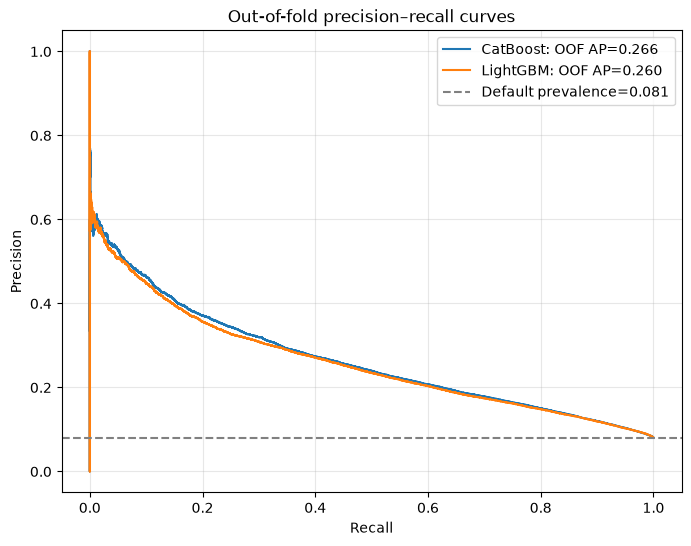

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve

y_array = y.to_numpy()

plt.figure(figsize=(8, 6))

for model_name, prob in oof_prob.items():
    precision, recall, _ = precision_recall_curve(y_array, prob)
    oof_ap = average_precision_score(y_array, prob)

    plt.plot(recall, precision, label=f"{model_name}: OOF AP={oof_ap:.3f}")

plt.axhline(
    y_array.mean(),
    color="gray",
    linestyle="--",
    label=f"Default prevalence={y_array.mean():.3f}",
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Out-of-fold precision–recall curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

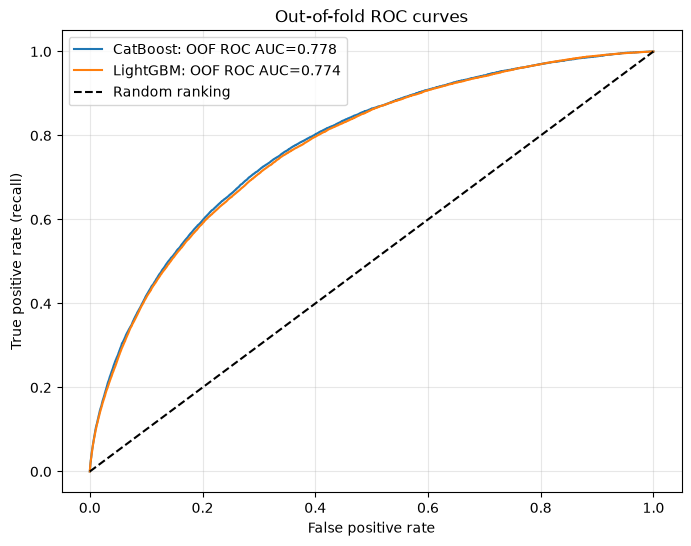

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

y_array = y.to_numpy()

plt.figure(figsize=(8, 6))

for model_name, prob in oof_prob.items():
    fpr, tpr, _ = roc_curve(y_array, prob)
    auc = roc_auc_score(y_array, prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name}: OOF ROC AUC={auc:.3f}",
    )

plt.plot([0, 1], [0, 1], "k--", label="Random ranking")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("Out-of-fold ROC curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

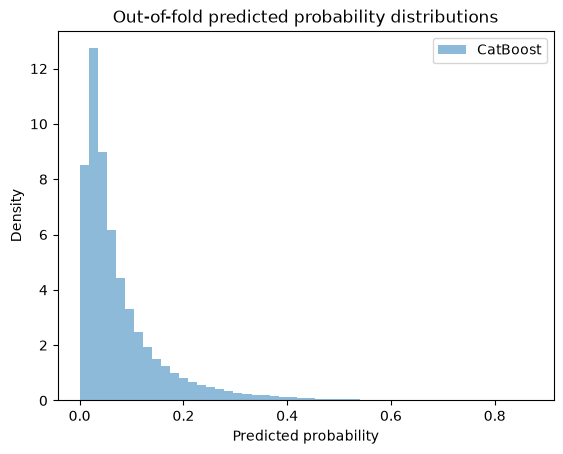

In [26]:
plt.hist(oof_prob['CatBoost'], bins=50, alpha=0.5, density=True, label='CatBoost')
plt.xlabel("Predicted probability")
plt.ylabel("Density")
plt.title("Out-of-fold predicted probability distributions")
plt.legend()

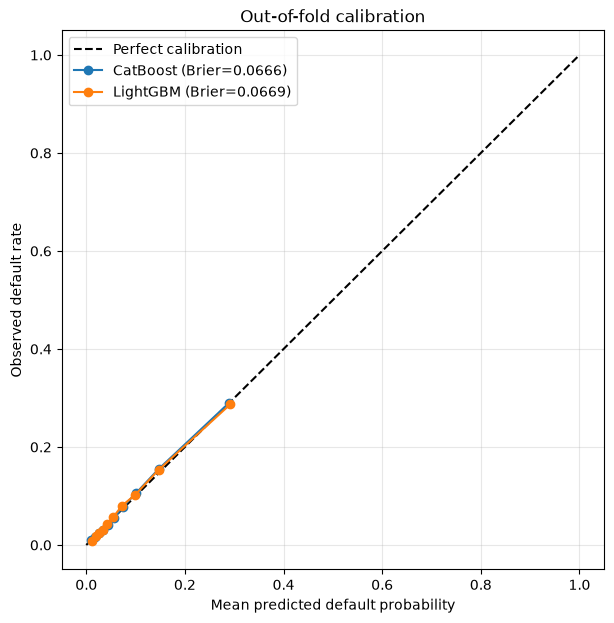

In [17]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

plt.figure(figsize=(7, 7))
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")

for model_name, prob in oof_prob.items():
    observed_rate, mean_predicted = calibration_curve(
        y_array,
        prob,
        n_bins=10,
        strategy="quantile",
    )
    plt.plot(
        mean_predicted,
        observed_rate,
        marker="o",
        label=(
            f"{model_name} "
            f"(Brier={brier_score_loss(y_array, prob):.4f})"
        ),
    )

plt.xlabel("Mean predicted default probability")
plt.ylabel("Observed default rate")
plt.title("Out-of-fold calibration")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [18]:
capacity_rows = []

for model_name, prob in oof_prob.items():
    ranked_idx = np.argsort(-prob)  # Highest predicted risk first

    for fraction in [0.05, 0.10]:
        n_reviewed = int(np.ceil(len(prob) * fraction))
        reviewed_idx = ranked_idx[:n_reviewed]

        defaults_found = int(y_array[reviewed_idx].sum())
        total_defaults = int(y_array.sum())

        capacity_rows.append({
            "model": model_name,
            "review_top_pct": fraction * 100,
            "reviewed": n_reviewed,
            "defaults_found": defaults_found,
            "precision": defaults_found / n_reviewed,
            "recall": defaults_found / total_defaults,
        })

capacity_df = pd.DataFrame(capacity_rows)
display(capacity_df)

,model,review_top_pct,reviewed,defaults_found,precision,recall
0,CatBoost,5.0,12301,4420,0.359320,0.222558
1,CatBoost,10.0,24601,7134,0.289988,0.359215
2,LightGBM,5.0,12301,4276,0.347614,0.215307
3,LightGBM,10.0,24601,7058,0.286899,0.355388


Paired fold comparison

In [28]:
ap_by_fold = fold_results_df.pivot(
    index="fold",
    columns="model",
    values="val_average_precision",
)

ap_by_fold["catboost_minus_lightgbm"] = (
    ap_by_fold["CatBoost"] - ap_by_fold["LightGBM"]
)

display(ap_by_fold)
print(
    "Mean AP difference:",
    f"{ap_by_fold['catboost_minus_lightgbm'].mean():.4f}",
)

model,CatBoost,LightGBM,catboost_minus_lightgbm
fold,,,
0,0.262400,0.255732,0.006669
1,0.263886,0.257815,0.006072
2,0.271632,0.264693,0.006939
3,0.269806,0.264837,0.004969
4,0.262912,0.256906,0.006007


Mean AP difference: 0.0061


# Catboost Tuning

In [33]:
import optuna
import mlflow

from sklearn.metrics import (
    average_precision_score,
    log_loss,
    roc_auc_score,
)
from lightgbm import early_stopping

def tune_holdout_model(
    *,
    study_name,
    model_family,
    model_class,
    suggest_params,
    fixed_params,
    baseline_params,
    prepare_frame,
    fit_model,
    best_iteration,
    X_train_raw,
    y_train,
    X_val_raw,
    y_val,
    n_trials=20,
    storage="sqlite:///optuna_holdout.db",
):
    """Tune one model on a fixed development/validation split."""
    X_train = prepare_frame(X_train_raw)
    X_val = prepare_frame(X_val_raw)

    if X_train.columns.tolist() != X_val.columns.tolist():
        raise ValueError("Training and validation feature columns differ.")

    def objective(trial):
        tuned_params = suggest_params(trial)
        model_params = {**fixed_params, **tuned_params}
        model = model_class(**model_params)

        with mlflow.start_run(
            run_name=f"{study_name}-trial-{trial.number}"
        ) as run:
            trial.set_user_attr("mlflow_run_id", run.info.run_id)

            mlflow.set_tags({
                "model_family": model_family,
                "stage": "holdout_tuning",
                "study_name": study_name,
                "feature_set": "final_selected_columns",
            })
            mlflow.log_params(model_params)
            mlflow.log_params({
                "trial_number": trial.number,
                "n_train": len(y_train),
                "n_validation": len(y_val),
                "n_features": X_train.shape[1],
            })
            mlflow.log_dict(
                {"columns": X_train.columns.tolist()},
                "schema/selected_features.json",
            )

            fit_model(model, X_train, y_train, X_val, y_val)
            val_prob = model.predict_proba(X_val)[:, 1]

            metrics = {
                "val_average_precision": average_precision_score(
                    y_val, val_prob
                ),
                "val_roc_auc": roc_auc_score(y_val, val_prob),
                "val_log_loss": log_loss(y_val, val_prob),
                "best_iteration": int(best_iteration(model)),
            }
            mlflow.log_metrics(metrics)

        return metrics["val_average_precision"]

    study = optuna.create_study(
        study_name=study_name,
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=42),
        storage=storage,
        load_if_exists=True,
    )

    # Run the existing baseline under the same tuning setup first.
    study.enqueue_trial(baseline_params, skip_if_exists=True)
    study.optimize(objective, n_trials=n_trials, n_jobs=1)

    return study

In [11]:
tune_train_idx, tune_val_idx = next(cv.split(X, y))

X_tune_train_raw = X.iloc[tune_train_idx].copy()
y_tune_train = y.iloc[tune_train_idx].copy()

X_tune_val_raw = X.iloc[tune_val_idx].copy()
y_tune_val = y.iloc[tune_val_idx].copy()

assert X_tune_train_raw.index.equals(y_tune_train.index)
assert X_tune_val_raw.index.equals(y_tune_val.index)

print("Development:", X_tune_train_raw.shape, y_tune_train.shape)
print("Validation: ", X_tune_val_raw.shape, y_tune_val.shape)

Development: (196806, 60) (196806,)
Validation:  (49202, 60) (49202,)


In [44]:
def suggest_catboost_params(trial):
    return {
        "depth": trial.suggest_int("depth", 4, 8),
        "l2_leaf_reg": trial.suggest_float(
            "l2_leaf_reg", 1.0, 10.0
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.015, 0.08, log=True
        ),
        "random_strength": trial.suggest_float(
            "random_strength", 0.0, 2.0
        ),
        "auto_class_weights": trial.suggest_categorical(
            "auto_class_weights",
            [None, "Balanced"],
        ),
    }


def fit_catboost(model, X_train, y_train, X_val, y_val):
    cat_cols = X_train.select_dtypes(
        include=["object", "string", "category"]
    ).columns.tolist()

    model.fit(
        X_train,
        y_train,
        cat_features=cat_cols,
        eval_set=(X_val, y_val),
        use_best_model=True,
    )


catboost_fixed_params = {
    "iterations": 3000,
    "loss_function": "Logloss",
    "eval_metric": "AUC",
    "random_seed": 42,
    "verbose": False,
    "early_stopping_rounds": 100,
}

catboost_baseline = {
    "depth": 6,
    "l2_leaf_reg": 3.0,
    "learning_rate": 0.03,
    "random_strength": 1.0,
    "auto_class_weights": None,
}

catboost_study = tune_holdout_model(
    study_name="catboost-holdout-ap-v1",
    model_family="catboost",
    model_class=CatBoostClassifier,
    suggest_params=suggest_catboost_params,
    fixed_params=catboost_fixed_params,
    baseline_params=catboost_baseline,
    prepare_frame=prepare_catboost_frame,
    fit_model=fit_catboost,
    best_iteration=lambda model: model.best_iteration_,
    X_train_raw=X_tune_train_raw,
    y_train=y_tune_train,
    X_val_raw=X_tune_val_raw,
    y_val=y_tune_val,
    n_trials=12,
)

print("Best validation AP:", catboost_study.best_value)
print("Best parameters:", catboost_study.best_params)
print(
    "MLflow run:",
    catboost_study.best_trial.user_attrs["mlflow_run_id"],
)

[I 2026-11-07 19:12:02,769] Using an existing study with `study_name='catboost-holdout-ap-v1'` instead of creating a new one.
[I 2026-11-07 19:12:02,775] Trial with params {'depth': 6, 'l2_leaf_reg': 3.0, 'learning_rate': 0.03, 'random_strength': 1.0, 'auto_class_weights': None} already exists. Skipping enqueue.
[I 2026-11-07 19:13:18,411] Trial 1 finished with value: 0.2637390671417012 and parameters: {'depth': 5, 'l2_leaf_reg': 9.556428757689245, 'learning_rate': 0.05107988650278712, 'random_strength': 1.1973169683940732, 'auto_class_weights': None}. Best is trial 1 with value: 0.2637390671417012.


🏃 View run catboost-holdout-ap-v1-trial-1 at: http://127.0.0.1:5000/#/experiments/1/runs/ce08758483ff4f21bc1499ecfca12115
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


[I 2026-11-07 19:14:15,732] Trial 2 finished with value: 0.2594677930041024 and parameters: {'depth': 4, 'l2_leaf_reg': 8.795585311974417, 'learning_rate': 0.041029961356831984, 'random_strength': 1.416145155592091, 'auto_class_weights': 'Balanced'}. Best is trial 1 with value: 0.2637390671417012.


🏃 View run catboost-holdout-ap-v1-trial-2 at: http://127.0.0.1:5000/#/experiments/1/runs/2fd1e41699a94d3596d3eb7a779b4fd6
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


[I 2026-11-07 19:15:46,772] Trial 3 finished with value: 0.25865022258463605 and parameters: {'depth': 8, 'l2_leaf_reg': 2.9110519961044856, 'learning_rate': 0.020336573418102074, 'random_strength': 0.36680901970686763, 'auto_class_weights': 'Balanced'}. Best is trial 1 with value: 0.2637390671417012.


🏃 View run catboost-holdout-ap-v1-trial-3 at: http://127.0.0.1:5000/#/experiments/1/runs/31fe679f7f4f4d3781bec8d205c8c57d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


... (14 outputs left out)

[I 2026-11-07 19:28:52,211] Trial 11 finished with value: 0.26313003155478154 and parameters: {'depth': 7, 'l2_leaf_reg': 8.216022512975824, 'learning_rate': 0.06768514930947905, 'random_strength': 1.0530708295295759, 'auto_class_weights': None}. Best is trial 1 with value: 0.2637390671417012.


🏃 View run catboost-holdout-ap-v1-trial-11 at: http://127.0.0.1:5000/#/experiments/1/runs/c60473f7789c4ca1898aef76157f9609
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


[I 2026-11-07 19:29:52,214] Trial 12 finished with value: 0.2604081613709377 and parameters: {'depth': 7, 'l2_leaf_reg': 8.557881283845996, 'learning_rate': 0.07229655287672662, 'random_strength': 0.9111582401720446, 'auto_class_weights': None}. Best is trial 1 with value: 0.2637390671417012.


🏃 View run catboost-holdout-ap-v1-trial-12 at: http://127.0.0.1:5000/#/experiments/1/runs/538a5a9aa21349c38c580e67a1b712e3
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Best validation AP: 0.2637390671417012
Best parameters: {'depth': 5, 'l2_leaf_reg': 9.556428757689245, 'learning_rate': 0.05107988650278712, 'random_strength': 1.1973169683940732, 'auto_class_weights': None}
MLflow run: ce08758483ff4f21bc1499ecfca12115


# LGBM Tuning

In [ ]:
def suggest_lgbm_params(trial):
    return {
        "num_leaves": trial.suggest_int("num_leaves", 15, 63),
        "min_child_samples": trial.suggest_int(
            "min_child_samples", 20, 200
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.015, 0.08, log=True
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 0.0, 10.0
        ),
        "is_unbalance": trial.suggest_categorical(
            "is_unbalance", [False, True]
        ),
    }

def fit_lgbm(model, X_train, y_train, X_val, y_val):
    if len(X_train) != len(y_train):
        raise ValueError(
            f"Training: {len(X_train)} feature rows, "
            f"{len(y_train)} labels"
        )
    if len(X_val) != len(y_val):
        raise ValueError(
            f"Validation: {len(X_val)} feature rows, "
            f"{len(y_val)} labels"
        )

    cat_cols = X_train.select_dtypes(
        include="category"
    ).columns.tolist()

    # Pass labels positionally; their original pandas indexes are irrelevant.
    model.fit(
        X_train.reset_index(drop=True),
        np.asarray(y_train, dtype=np.int8),
        eval_X=X_val.reset_index(drop=True),
        eval_y=np.asarray(y_val, dtype=np.int8),
        categorical_feature=cat_cols,
        callbacks=[
            early_stopping(
                stopping_rounds=150,
                first_metric_only=True,
                verbose=False,
            )
        ],
    )

lgbm_fixed_params = {
    "n_estimators": 3000,
    "objective": "binary",
    "metric": "average_precision",
    "random_state": 42,
    "verbosity": -1,
    "n_jobs": -1,
}

lgbm_baseline = {
    "num_leaves": 31,
    "min_child_samples": 20,
    "learning_rate": 0.03,
    "reg_lambda": 0.0,
    "is_unbalance": False,
}
lgbm_study = tune_holdout_model(
    study_name="lightgbm-holdout-ap-v2",
    model_family="lightgbm",
    model_class=LGBMClassifier,
    suggest_params=suggest_lgbm_params,
    fixed_params=lgbm_fixed_params,
    baseline_params=lgbm_baseline,
    prepare_frame=prepare_lightgbm_frame,
    fit_model=fit_lgbm,
    best_iteration=lambda model: model.best_iteration_,
    X_train_raw=X_tune_train_raw,
    y_train=y_tune_train,
    X_val_raw=X_tune_val_raw,
    y_val=y_tune_val,
    n_trials=20,
)

print("Best validation AP:", lgbm_study.best_value)
print("Best parameters:", lgbm_study.best_params)
print(
    "MLflow run:",
    lgbm_study.best_trial.user_attrs["mlflow_run_id"],
)

[I 2026-11-07 18:59:08,131] A new study created in RDB with name: lightgbm-holdout-ap-v2
[I 2026-11-07 18:59:13,492] Trial 0 finished with value: 0.25444425897124967 and parameters: {'num_leaves': 31, 'min_child_samples': 20, 'learning_rate': 0.03, 'reg_lambda': 0.0, 'is_unbalance': False}. Best is trial 0 with value: 0.25444425897124967.


🏃 View run lightgbm-holdout-ap-v2-trial-0 at: http://127.0.0.1:5000/#/experiments/1/runs/54a062d19ce44d0c835accf4112d9608
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


[I 2026-11-07 18:59:18,281] Trial 1 finished with value: 0.25696986110700176 and parameters: {'num_leaves': 33, 'min_child_samples': 192, 'learning_rate': 0.05107988650278712, 'reg_lambda': 5.986584841970366, 'is_unbalance': False}. Best is trial 1 with value: 0.25696986110700176.


🏃 View run lightgbm-holdout-ap-v2-trial-1 at: http://127.0.0.1:5000/#/experiments/1/runs/65a9e916fc3d42269dbd8130cbd89663
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


[I 2026-11-07 18:59:23,798] Trial 2 finished with value: 0.2563789068982075 and parameters: {'num_leaves': 17, 'min_child_samples': 176, 'learning_rate': 0.041029961356831984, 'reg_lambda': 7.080725777960454, 'is_unbalance': True}. Best is trial 1 with value: 0.25696986110700176.


🏃 View run lightgbm-holdout-ap-v2-trial-2 at: http://127.0.0.1:5000/#/experiments/1/runs/6e980391c2b14f5eaaa1312aa68eae88
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


... (30 outputs left out)

[I 2026-11-07 19:02:04,233] Trial 18 finished with value: 0.2587176915577211 and parameters: {'num_leaves': 18, 'min_child_samples': 101, 'learning_rate': 0.020478288266639267, 'reg_lambda': 7.760464981879895, 'is_unbalance': False}. Best is trial 12 with value: 0.25879684113808.


🏃 View run lightgbm-holdout-ap-v2-trial-18 at: http://127.0.0.1:5000/#/experiments/1/runs/cf029070a1fc4827a43f05dcb7bc0af1
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


[I 2026-11-07 19:02:15,409] Trial 19 finished with value: 0.2596230249674658 and parameters: {'num_leaves': 17, 'min_child_samples': 102, 'learning_rate': 0.018918557796614686, 'reg_lambda': 6.977441186050545, 'is_unbalance': False}. Best is trial 19 with value: 0.2596230249674658.


🏃 View run lightgbm-holdout-ap-v2-trial-19 at: http://127.0.0.1:5000/#/experiments/1/runs/d11d1e4037d545469235e13dae2c7b83
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Best validation AP: 0.2596230249674658
Best parameters: {'num_leaves': 17, 'min_child_samples': 102, 'learning_rate': 0.018918557796614686, 'reg_lambda': 6.977441186050545, 'is_unbalance': False}
MLflow run: d11d1e4037d545469235e13dae2c7b83


# Final Model Selection
- Choose from validation results, fit on all development data, and evaluate once on the held-out test set
- Save the inference

CatBoost is the current choice: its best holdout AP is 0.263739, versus 0.259623 for LightGBM.
- get the winning model's parameters 


In [9]:
WINNING_RUN_ID = "ce08758483ff4f21bc1499ecfca12115"
winning_run = mlflow.get_run(WINNING_RUN_ID)

if winning_run.info.status != "FINISHED":
    raise ValueError(f"Run status: {winning_run.info.status}")

if winning_run.data.tags.get("model_family") != "catboost":
    raise ValueError("The selected run is not a CatBoost run.")

p = winning_run.data.params
m = winning_run.data.metrics

final_iterations = int(m["best_iteration"]) + 1

final_params = {
    "iterations": final_iterations,
    "learning_rate": float(p["learning_rate"]),
    "depth": int(p["depth"]),
    "l2_leaf_reg": float(p["l2_leaf_reg"]),
    "random_strength": float(p["random_strength"]),
    "auto_class_weights": (
        None
        if p.get("auto_class_weights") in (None, "None")
        else p["auto_class_weights"]
    ),
    "loss_function": p["loss_function"],
    "eval_metric": p["eval_metric"],
    "random_seed": int(p["random_seed"]),
    "verbose": False,
}

print("Winning run:", WINNING_RUN_ID)
print("Tuning validation AP:", m["val_average_precision"])
print("Final tree count:", final_iterations)
display(final_params)

Winning run: ce08758483ff4f21bc1499ecfca12115
Tuning validation AP: 0.2637390671417012
Final tree count: 1494


{'iterations': 1494,
 'learning_rate': 0.05107988650278712,
 'depth': 5,
 'l2_leaf_reg': 9.556428757689245,
 'random_strength': 1.1973169683940732,
 'auto_class_weights': None,
 'loss_function': 'Logloss',
 'eval_metric': 'AUC',
 'random_seed': 42,
 'verbose': False}

Set the decision rule using development data: Top 10%.

In [13]:
from sklearn.metrics import precision_score, recall_score

X_threshold_train = prepare_catboost_frame(X_tune_train_raw)
X_threshold_val = prepare_catboost_frame(X_tune_val_raw)

cat_cols = X_threshold_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

threshold_model = CatBoostClassifier(**final_params)
threshold_model.fit(
    X_threshold_train,
    y_tune_train,
    cat_features=cat_cols,
)

threshold_val_prob = threshold_model.predict_proba(
    X_threshold_val
)[:, 1]

review_fraction = 0.10  # Replace with the agreed review capacity
decision_threshold = float(
    np.quantile(threshold_val_prob, 1 - review_fraction)
)

val_flagged = threshold_val_prob >= decision_threshold

print(f"Threshold: {decision_threshold:.6f}")
print(f"Flagged: {val_flagged.mean():.2%} of validation applicants")
print(f"Precision: {precision_score(y_tune_val, val_flagged):.3f}")
print(f"Recall: {recall_score(y_tune_val, val_flagged):.3f}")
print(
    "Mean predicted risk / observed default rate:",
    f"{threshold_val_prob.mean():.3f} / {y_tune_val.mean():.3f}",
)

Threshold: 0.184522
Flagged: 10.00% of validation applicants
Precision: 0.293
Recall: 0.363
Mean predicted risk / observed default rate: 0.080 / 0.081


#### Retrain on all development data and save locally

In [ ]:
from pathlib import Path
import json

from credit_default_risk.config import PROJECT_ROOT

X_final = prepare_catboost_frame(X)
final_cat_cols = X_final.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

final_model = CatBoostClassifier(**final_params)
final_model.fit(
    X_final,
    y,
    cat_features=final_cat_cols,
)

model_dir = PROJECT_ROOT / "artifacts" / "catboost_final"
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "model.cbm"
manifest_path = model_dir / "manifest.json"

final_model.save_model(str(model_path))

manifest = {
    "model_family": "CatBoost",
    "source_mlflow_run_id": WINNING_RUN_ID,
    "feature_columns": X_final.columns.tolist(),
    "categorical_columns": final_cat_cols,
    "parameters": final_params,
    "positive_class": 1,
    "probability_output": "predict_proba(X)[:, 1]",
    "decision_threshold": decision_threshold,
    "threshold_policy": f"top {review_fraction:.0%} on tuning validation",
}

manifest_path.write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8",
)

print("Saved model:", model_path)
print("Saved manifest:", manifest_path)

In [ ]:
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)

test_df = pd.read_parquet(PROCESSED_TEST_PATH)
if test_df[ID_COL].isna().any() or test_df[ID_COL].duplicated().any():
    raise ValueError(f"Test data must have unique, non-null {ID_COL}")
if test_df[TARGET_COL].isna().any() or not test_df[TARGET_COL].isin([0, 1]).all():
    raise ValueError(f"Test data must have binary, non-null {TARGET_COL}")

X_test = prepare_catboost_frame(
    select_final_features(test_df, manifest["feature_columns"])
)
y_test = test_df[TARGET_COL].astype("int8")
if X_test.columns.tolist() != manifest["feature_columns"]:
    raise ValueError("Test features differ from the final model manifest")

test_prob = final_model.predict_proba(X_test)[:, 1]
test_flagged = test_prob >= decision_threshold
test_metrics = {
    "test_average_precision": average_precision_score(y_test, test_prob),
    "test_roc_auc": roc_auc_score(y_test, test_prob),
    "test_log_loss": log_loss(y_test, test_prob),
    "test_brier_score": brier_score_loss(y_test, test_prob),
    "test_default_rate": float(y_test.mean()),
    "test_review_rate": float(test_flagged.mean()),
    "test_precision_at_threshold": precision_score(
        y_test, test_flagged, zero_division=0
    ),
    "test_recall_at_threshold": recall_score(
        y_test, test_flagged, zero_division=0
    ),
}
display(pd.Series(test_metrics, name="Final test"))

In [ ]:
from mlflow import MlflowClient

REGISTERED_MODEL_NAME = "credit-default-risk-catboost"
MODEL_ALIAS = "champion"

with mlflow.start_run(run_name="catboost-final") as final_run:
    mlflow.set_tags({
        "model_family": "catboost",
        "stage": "final_test",
        "source_tuning_run_id": WINNING_RUN_ID,
    })
    mlflow.log_params(final_params)
    mlflow.log_metrics(test_metrics)
    mlflow.log_dict(manifest, "inference/manifest.json")
    model_info = mlflow.catboost.log_model(
        final_model,
        name="model",
        input_example=X_final.head(5),
        metadata={
            "probability_output": "native predict_proba(X)[:, 1]"
        },
    )

registered_version = mlflow.register_model(
    model_uri=model_info.model_uri,
    name=REGISTERED_MODEL_NAME,
)
MlflowClient().set_registered_model_alias(
    REGISTERED_MODEL_NAME, MODEL_ALIAS, registered_version.version
)

print("Final MLflow run:", final_run.info.run_id)
print("Registered version:", registered_version.version)
print("Alias:", MODEL_ALIAS)